# Week 11: Customer Segmentation & Prediction
This notebook compares three clustering algorithms and builds separate Random Forest churn models for K-Means customer segments. Churn is excluded from clustering to prevent target leakage.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
df=pd.read_csv('segmentation_data.csv')
print('Shape:',df.shape,' Missing:',int(df.isna().sum().sum()),' Duplicates:',int(df.duplicated().sum()))
display(df.head()); display(df['Churn'].value_counts().to_frame('count'))
ID='CustomerID' if 'CustomerID' in df else None
TARGET='Churn'; features=[c for c in df.columns if c not in [ID,TARGET,'SegmentID','SegmentName']]
num=df[features].select_dtypes(include=np.number).columns.tolist(); cat=[c for c in features if c not in num]
prep=ColumnTransformer([('num',Pipeline([('imp',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('oh',OneHotEncoder(handle_unknown='ignore'))]),cat)])
X=prep.fit_transform(df[features]); X=X.toarray() if hasattr(X,'toarray') else X


Shape: (500, 11)  Missing: 0  Duplicates: 0


,CustomerID,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,Churn,SegmentID,SegmentName
0,C00001,6,64,1540,One year,Credit Card,No,1,0,1,Developing / Mixed
1,C00002,21,113,1753,Month-to-month,Electronic Check,Yes,1,0,1,Developing / Mixed
2,C00003,27,31,1455,Two year,Credit Card,No,1,0,1,Developing / Mixed
3,C00004,53,29,7150,Month-to-month,Electronic Check,No,1,0,1,Developing / Mixed
4,C00005,16,185,1023,One year,Electronic Check,No,1,0,1,Developing / Mixed


,count
Churn,
0,447
1,53


## 1. Elbow method and clustering comparison

  File "c:\Users\shari\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\shari\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\shari\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\shari\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


,k,inertia,silhouette
0,2,2406.523536,0.172872
1,3,2196.764280,0.146420
2,4,2013.920615,0.141203
3,5,1883.607062,0.137058
4,6,1772.395604,0.135301


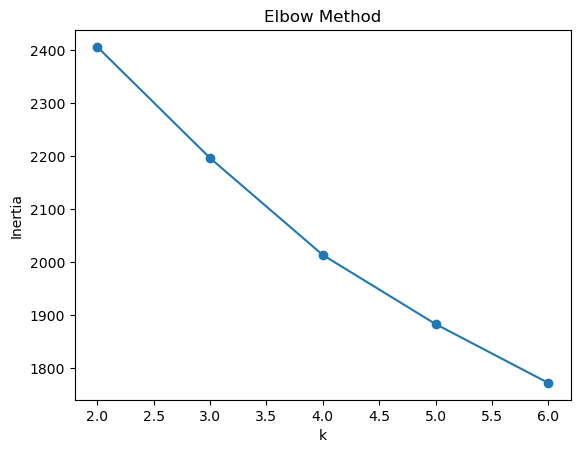

,algorithm,clusters_excluding_noise,noise_points,silhouette
0,K-Means,3,0,0.14642
1,Hierarchical,3,0,0.11494
2,DBSCAN,6,344,-0.12483


In [2]:
elbow=[]
for k in range(2,7):
 m=KMeans(n_clusters=k,random_state=42,n_init=10).fit(X)
 elbow.append({'k':k,'inertia':m.inertia_,'silhouette':silhouette_score(X,m.labels_)})
elbow=pd.DataFrame(elbow); display(elbow)
plt.plot(elbow.k,elbow.inertia,marker='o'); plt.xlabel('k'); plt.ylabel('Inertia'); plt.title('Elbow Method'); plt.show()
labels=KMeans(n_clusters=3,random_state=42,n_init=10).fit_predict(X)
hier=AgglomerativeClustering(n_clusters=3).fit_predict(X)
db=DBSCAN(eps=1.5,min_samples=8).fit_predict(X)
def q(l):
 l=np.asarray(l); score=np.nan
 try:
  if len(set(l))>1: score=silhouette_score(X,l)
 except: pass
 return {'clusters_excluding_noise':len(set(l)-{-1}),'noise_points':int((l==-1).sum()),'silhouette':score}
comparison=pd.DataFrame([{'algorithm':'K-Means',**q(labels)},{'algorithm':'Hierarchical',**q(hier)},{'algorithm':'DBSCAN',**q(db)}])
display(comparison)
df['SegmentID']=labels


## 2. Segment profiling

In [3]:
rows=[]
for sid,g in df.groupby('SegmentID'):
 r={'SegmentID':int(sid),'Customers':len(g),'Share (%)':round(100*len(g)/len(df),1),'Churn rate (%)':round(100*g.Churn.mean(),1)}
 for c in num:r['Avg '+c]=round(g[c].mean(),2)
 for c in cat:
  mode=g[c].mode(); r['Most common '+c]=mode.iloc[0] if len(mode) else 'Unknown'
 rows.append(r)
profiles=pd.DataFrame(rows)
tmed=df.Tenure.median(); mmed=df.MonthlyCharges.median()
def naming(r):
 t,m=r.get('Avg Tenure',np.nan),r.get('Avg MonthlyCharges',np.nan)
 if pd.notna(t) and pd.notna(m):
  if t>=tmed and m>=mmed:return 'Established High-Value'
  if t<tmed and m>=mmed:return 'Newer High-Charge'
  if t>=tmed and m<mmed:return 'Long-Tenure Value'
 return 'Developing / Mixed'
profiles['Suggested segment name']=profiles.apply(naming,axis=1)
display(profiles)


,SegmentID,Customers,Share (%),Churn rate (%),Avg Tenure,Avg MonthlyCharges,Avg TotalCharges,Avg SeniorCitizen,Most common Contract,Most common PaymentMethod,Most common PaperlessBilling,Suggested segment name
0,0,114,22.8,8.8,39.54,97.83,6239.81,0.0,One year,Credit Card,No,Long-Tenure Value
1,1,249,49.8,10.0,35.70,108.14,4274.98,1.0,Month-to-month,Credit Card,No,Developing / Mixed
2,2,137,27.4,13.1,35.54,136.77,2504.63,0.0,One year,Electronic Check,Yes,Newer High-Charge


## 3. Segment-specific Random Forests and GridSearchCV

In [4]:
name_map=dict(zip(profiles.SegmentID,profiles['Suggested segment name']))
results=[]
for sid,g in df.groupby('SegmentID'):
 name=name_map[sid]
 if len(g)<15 or g.Churn.nunique()<2:
  results.append({'Segment':name,'Rows':len(g),'Status':'Insufficient rows/classes','Accuracy':np.nan,'Precision':np.nan,'Recall':np.nan,'F1':np.nan,'ROC_AUC':np.nan}); continue
 Xs=g[features]; ys=g.Churn.astype(int)
 Xtr,Xte,ytr,yte=train_test_split(Xs,ys,test_size=.25,random_state=42,stratify=ys if ys.value_counts().min()>=2 else None)
 nn=Xtr.select_dtypes(include=np.number).columns.tolist(); cc=[c for c in Xtr if c not in nn]
 pp=ColumnTransformer([('num',Pipeline([('imp',SimpleImputer(strategy='median')),('scale',StandardScaler())]),nn),('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('oh',OneHotEncoder(handle_unknown='ignore'))]),cc)])
 pipe=Pipeline([('prep',pp),('rf',RandomForestClassifier(random_state=42,class_weight='balanced'))])
 folds=min(3,int(ytr.value_counts().min()))
 if folds>=2:
  gs=GridSearchCV(pipe,{'rf__n_estimators':[100,200],'rf__max_depth':[None,5,10],'rf__min_samples_leaf':[1,2]},scoring='f1',cv=StratifiedKFold(n_splits=folds,shuffle=True,random_state=42),n_jobs=-1)
  gs.fit(Xtr,ytr); model=gs.best_estimator_; print(name,'best parameters:',gs.best_params_)
 else: model=pipe.fit(Xtr,ytr)
 pred=model.predict(Xte); proba=model.predict_proba(Xte)[:,1]
 auc=roc_auc_score(yte,proba) if yte.nunique()==2 else np.nan
 results.append({'Segment':name,'Rows':len(g),'Status':'Evaluated','Accuracy':accuracy_score(yte,pred),'Precision':precision_score(yte,pred,zero_division=0),'Recall':recall_score(yte,pred,zero_division=0),'F1':f1_score(yte,pred,zero_division=0),'ROC_AUC':auc})
evaluation=pd.DataFrame(results); display(evaluation)
evaluation.to_csv('model_evaluation_results.csv',index=False)
profiles.to_csv('segment_profiles.csv',index=False)


Long-Tenure Value best parameters: {'rf__max_depth': None, 'rf__min_samples_leaf': 2, 'rf__n_estimators': 100}
Developing / Mixed best parameters: {'rf__max_depth': None, 'rf__min_samples_leaf': 1, 'rf__n_estimators': 100}
Newer High-Charge best parameters: {'rf__max_depth': None, 'rf__min_samples_leaf': 2, 'rf__n_estimators': 100}


,Segment,Rows,Status,Accuracy,Precision,Recall,F1,ROC_AUC
0,Long-Tenure Value,114,Evaluated,0.896552,0.0,0.000000,0.000000,0.961538
1,Developing / Mixed,249,Evaluated,0.984127,1.0,0.833333,0.909091,1.000000
2,Newer High-Charge,137,Evaluated,0.971429,1.0,0.800000,0.888889,0.993333


## 4. Business recommendations and limitations
- Established High-Value: proactive retention and loyalty benefits, avoiding blanket discounts.
- Newer High-Charge: improve onboarding, billing clarity, and early service support.
- Long-Tenure Value: offer relevant bundles and reward loyalty while protecting margin.
- Developing / Mixed: test targeted interventions rather than assuming homogeneous needs.

Use held-out test data and cross-validation to reduce overfitting. Tune tree depth and leaf size. Small segments can yield unstable metrics, and ROC-AUC is undefined when a test split contains only one class. DBSCAN may identify noise and needs parameter validation. Segment labels are heuristic, and business uplift must be measured through controlled experiments.